# Demonstração — Grafo de Conhecimento Clínico com Espaço Vetorial de N-gramas

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cl4nyz/Natural-Language-Processing/blob/main/project2/pipelines/notebooks/demo_projeto2.ipynb)

Este notebook executa, lado a lado, os dois pipelines comparados no Projeto 2:

| | Projeto 1 (baseline) | Projeto 2 |
| --- | --- | --- |
| Script | `src/project1/02_pos_tagging_pipeline.py` | `project2/src/02_project2_pos_tagging_pipeline.py` |
| Classificação de entidades | busca exata no dicionário `medical_vocab.json` | TF-IDF de 1-2-gramas + vizinho mais próximo por cosseno (limiar 0,35) |

Os dois compartilham tokenização, POS-tagging, chunking e as regras de relação, então **toda diferença entre os grafos vem do classificador de entidades**.

Roteiro:
1. Preparação do ambiente
2. O espaço vetorial de N-gramas
3. Classificação de sintagmas: dicionário × N-gramas
4. Grafos de um caso clínico (tabelas, métricas e visualização)
5. Sensibilidade ao limiar de similaridade
6. Comparação em vários casos do MultiCaRe

> Para analisar outro caso ou outro limiar, altere `CASE_IDX` / `THRESHOLD` na seção 4 e reexecute as células seguintes.

## 1. Preparação do ambiente

Localiza a raiz do repositório (ou o clona, quando executado no Colab/Binder), instala as dependências e importa os dois pipelines **sem modificá-los**.

In [1]:
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/Cl4nyz/Natural-Language-Processing.git"

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "project2" / "src").is_dir() and (p / "src" / "project1").is_dir():
            return p
    return None

ROOT = find_repo_root()
if ROOT is None:  # Colab / Binder: o notebook foi aberto fora do repositório
    if not Path("Natural-Language-Processing").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    ROOT = Path("Natural-Language-Processing").resolve()

os.chdir(ROOT)  # os scripts resolvem caminhos a partir da raiz do repositório
print("Raiz do repositório:", ROOT)

Raiz do repositório: /home/f-ec2023/ra214381/Desktop/Natural-Language-Processing


In [2]:
%pip install -q nltk scikit-learn pandas networkx tabulate matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import importlib.util
import functools
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

p1 = load_module("projeto1", "src/project1/02_pos_tagging_pipeline.py")
p2 = load_module("projeto2", "project2/src/02_project2_pos_tagging_pipeline.py")

cases = pd.read_csv("project2/data/raw/cases.csv")
print(f"{len(cases)} casos clínicos carregados")

56 casos clínicos carregados


## 2. O espaço vetorial de N-gramas

Cada termo do vocabulário médico do Projeto 1 é um **protótipo rotulado** com sua categoria. O `TfidfVectorizer(ngram_range=(1, 2))` transforma cada protótipo num vetor esparso cujas dimensões são unigramas e bigramas.

O IDF é calculado sobre os próprios protótipos: n-gramas que aparecem em muitos termos (pouco discriminativos) recebem peso baixo; n-gramas raros recebem peso alto.

In [4]:
features = p2.VECTORIZER.get_feature_names_out()
n_bigrams = sum(" " in f for f in features)
print(f"Protótipos (termos do vocabulário): {p2.X_VOCAB.shape[0]}")
print(f"Dimensões do espaço: {len(features)}  ({len(features) - n_bigrams} unigramas, {n_bigrams} bigramas)")
print("\nProtótipos por categoria:")
print(pd.Series(p2.TRAIN_CATEGORIES).value_counts().to_string())

Protótipos (termos do vocabulário): 274
Dimensões do espaço: 393  (313 unigramas, 80 bigramas)

Protótipos por categoria:
Symptom      71
Exam         54
Anatomy      45
Finding      39
Treatment    30
Diagnosis    21
Outcome      14


In [5]:
idf = pd.DataFrame({"n-grama": features, "idf": p2.VECTORIZER.idf_}).sort_values("idf")
print("N-gramas MENOS discriminativos (aparecem em vários protótipos):")
display(idf.head(8).reset_index(drop=True))
print("Exemplos de bigramas (cada um é uma dimensão própria do espaço):")
display(idf[idf["n-grama"].str.contains(" ")].sample(8, random_state=0).reset_index(drop=True))

N-gramas MENOS discriminativos (aparecem em vários protótipos):


,n-grama,idf
0,pain,4.670861
1,pancreas,5.007333
2,of,5.007333
3,blood,5.007333
4,pancreatitis,5.230477
5,the,5.230477
6,of the,5.230477
7,the pancreas,5.230477


Exemplos de bigramas (cada um é uma dimensão própria do espaço):


,n-grama,idf
0,nocturnal dyspnea,5.923624
1,flank pain,5.923624
2,epigastric pain,5.923624
3,weight loss,5.923624
4,mucinous neoplasm,5.923624
5,serous cystadenoma,5.923624
6,rebound tenderness,5.923624
7,spinal cord,5.923624


## 3. Classificação de sintagmas: dicionário × N-gramas

Para cada sintagma, mostramos a categoria atribuída pelo Projeto 1 (busca exata), a atribuída pelo Projeto 2, a maior similaridade de cosseno e **o protótipo mais próximo**, que explica a decisão do Projeto 2.

Os exemplos vêm do caso analisado no README e incluem acertos e erros do novo método.

In [6]:
def explain(phrase):
    cleaned = p2.clean_phrase(phrase).lower()
    sims = p2.cosine_similarity(p2.VECTORIZER.transform([cleaned]), p2.X_VOCAB)[0]
    best = sims.argmax()
    terms = [t for cat, ts in json.load(open(p2.VOCAB_FILE)).items() for t in ts]
    return {
        "sintagma": phrase,
        "Projeto 1": p1.classify_entity_generically(phrase),
        "Projeto 2": p2.classify_entity_vector_space(phrase),
        "similaridade": round(float(sims[best]), 3),
        "protótipo mais próximo": f"{terms[best]} ({p2.TRAIN_CATEGORIES[best]})" if sims[best] > 0 else "— (nenhum n-grama em comum)",
    }

import json
examples = [
    "invasive moderately to poorly differentiated adenocarcinoma",  # acerto: diagnóstico novo
    "gastroduodenal outlet obstruction",                             # acerto: bigrama parcial
    "postprandial abdominal fullness",                               # acerto: sintoma composto
    "superior mesenteric vessels",                                   # acerto: anatomia
    "intra-abdominal abscesses",                                     # erro de tipo (sem stemming)
    "failure",                                                       # ruído: casa com 'renal failure'
    "two days post-procedure",                                       # ruído: casa com 'whipple procedure'
    "CT",                                                            # regressão: filtro de 2 caracteres
    "Figure 1",                                                      # ruído descartado corretamente
]
pd.DataFrame([explain(e) for e in examples])

,sintagma,Projeto 1,Projeto 2,similaridade,protótipo mais próximo
0,invasive moderately to poorly differentiated a...,Unknown,Diagnosis,0.453,pancreatic ductal adenocarcinoma (Diagnosis)
1,gastroduodenal outlet obstruction,Unknown,Diagnosis,0.577,bowel obstruction (Diagnosis)
2,postprandial abdominal fullness,Unknown,Symptom,0.618,abdominal pain (Symptom)
3,superior mesenteric vessels,Unknown,Anatomy,0.680,superior mesenteric artery (Anatomy)
4,intra-abdominal abscesses,Unknown,Symptom,0.618,abdominal pain (Symptom)
5,failure,Unknown,Diagnosis,0.591,renal failure (Diagnosis)
6,two days post-procedure,Unknown,Treatment,0.577,whipple procedure (Treatment)
7,CT,Exam,Unknown,1.000,ct (Exam)
8,Figure 1,Unknown,Unknown,0.000,— (nenhum n-grama em comum)


In [7]:
# Teste seus próprios sintagmas:
pd.DataFrame([explain(e) for e in ["acute abdominal pain", "small bowel obstruction", "pancreatic cyst"]])

,sintagma,Projeto 1,Projeto 2,similaridade,protótipo mais próximo
0,acute abdominal pain,Symptom,Symptom,0.851,abdominal pain (Symptom)
1,small bowel obstruction,Diagnosis,Diagnosis,1.000,bowel obstruction (Diagnosis)
2,pancreatic cyst,Finding,Finding,0.732,cyst (Finding)


## 4. Grafos de um caso clínico

Os dois pipelines são executados sobre o mesmo texto. `CASE_IDX = 1` é o caso PMC9387390_01 discutido no README.

In [8]:
CASE_IDX = 1      # linha de cases.csv
THRESHOLD = 0.35  # limiar de similaridade do Projeto 2 (padrão do script)

def run_p2(text, threshold=0.35):
    # Executa o pipeline do Projeto 2 com outro limiar, sem alterar o script
    original = p2.classify_entity_vector_space
    p2.classify_entity_vector_space = functools.partial(original, threshold=threshold)
    try:
        return p2.build_generic_graph(text)
    finally:
        p2.classify_entity_vector_space = original

case = cases.loc[CASE_IDX]
text = case["case_text"]
print(f"{case['case_id']} | idade {case['age']:.0f} | {case['gender']}\n")
print(textwrap.fill(text[:900], 110) + " [...]")

g1 = p1.build_generic_graph(text)
g2 = run_p2(text, THRESHOLD)

PMC9387390_01 | idade 57 | Male

A 57-year-old man with no significant past medical or surgical history initially presented with postprandial
abdominal fullness and diarrhea. Computed tomography (CT) imaging showed nonspecific mesenteric edema. An
upper gastrointestinal (UGI) contrast study and barium enema were unremarkable. Approximately three months
later, a repeat CT of the abdomen demonstrated a central mesenteric mass abutting the pancreas, encasing the
superior mesenteric vessels, causing extrinsic narrowing of the second portion of the duodenum. The patient
underwent CT guided biopsy of the mass; this was consistent with invasive moderately to poorly differentiated
adenocarcinoma, thought to have arisen from the upper gastrointestinal tract and/or pancreaticobiliary tract.
Given his locally advanced disease, he was nonoperable and started on chemotherapy. Approximately 11 months
after the initiation of chemother [...]


In [9]:
TYPES = ["Symptom", "Exam", "Finding", "Anatomy", "Treatment", "Diagnosis", "Outcome", "ExamResult"]

def entities(g):
    return {(d.get("label", n).lower(), d["entity_type"]) for n, d in g.nodes(data=True) if d.get("entity_type") != "Patient"}

def metrics(g):
    ents = entities(g)
    row = {
        "nós (sem paciente)": len(ents),
        "arestas": g.number_of_edges(),
        "arestas entre entidades": sum(1 for u, v in g.edges() if "P1" not in (u, v)),
    }
    row.update({t: sum(1 for _, et in ents if et == t) for t in TYPES})
    return row

e1, e2 = entities(g1), entities(g2)
comparison = pd.DataFrame({"Projeto 1": metrics(g1), "Projeto 2": metrics(g2)})
comparison.loc["entidades em comum"] = [len(e1 & e2)] * 2
comparison.loc["entidades exclusivas"] = [len(e1 - e2), len(e2 - e1)]
comparison

,Projeto 1,Projeto 2
nós (sem paciente),22,36
arestas,30,51
arestas entre entidades,12,21
Symptom,4,7
Exam,6,7
Finding,4,6
Anatomy,4,5
Treatment,4,6
Diagnosis,0,5
Outcome,0,0


In [10]:
diff = pd.DataFrame(
    [(lbl, t, "só Projeto 1") for lbl, t in sorted(e1 - e2)] +
    [(lbl, t, "só Projeto 2") for lbl, t in sorted(e2 - e1)],
    columns=["entidade", "tipo", "origem"],
)
diff

,entidade,tipo,origem
0,ct,Exam,só Projeto 1
1,abdominal distention,Symptom,só Projeto 2
2,adenocarcinoma,Diagnosis,só Projeto 2
3,bilious fluid,Finding,só Projeto 2
4,complete gastric decompression,Exam,só Projeto 2
5,failure,Diagnosis,só Projeto 2
6,fluid,Finding,só Projeto 2
7,functional obstruction,Diagnosis,só Projeto 2
8,gastroduodenal outlet obstruction,Diagnosis,só Projeto 2
9,imaging,Exam,só Projeto 2


Tabelas de nós e arestas do Projeto 2 (mesmo formato do Projeto 1):

In [11]:
nodes_df, node_map = p2.generate_node_table(g2)
edges_df = p2.generate_edge_table(g2, node_map)
display(nodes_df)
display(edges_df)

,node_id,type,label,attributes
0,P1,Patient,57yo man patient,
1,S1,Symptom,Postprandial abdominal fullness,
2,S2,Symptom,Diarrhea,
3,E1,Exam,Tomography,
4,E2,Exam,Imaging,
5,S3,Symptom,Nonspecific mesenteric edema,
6,E3,Exam,Repeat ct,
7,F1,Finding,Central mesenteric mass,
8,A1,Anatomy,Pancreas,
9,A2,Anatomy,Superior mesenteric vessels,


,edge_id,source_id,target_id,relation,attributes
0,e1,P1,S1,PRESENTS_WITH,
1,e2,P1,S2,PRESENTS_WITH,
2,e3,P1,E1,UNDERWENT_EXAM,
3,e4,P1,E2,UNDERWENT_EXAM,
4,e5,P1,S3,PRESENTS_WITH,
5,e6,P1,E3,UNDERWENT_EXAM,
6,e7,P1,F1,HAS_FINDING,
7,e8,P1,E4,UNDERWENT_EXAM,
8,e9,P1,T1,TREATED_WITH,
9,e10,P1,F2,HAS_FINDING,


### Visualização

Cor **e** forma identificam o tipo de cada nó (a forma garante a leitura sem depender de cor). As arestas que saem do paciente ficam em cinza claro; as relações entre entidades (`LOCATED_AT`, `SUGGESTS`, `REVEALS`, `TARGETS`) ficam escuras e rotuladas, porque carregam o raciocínio clínico.

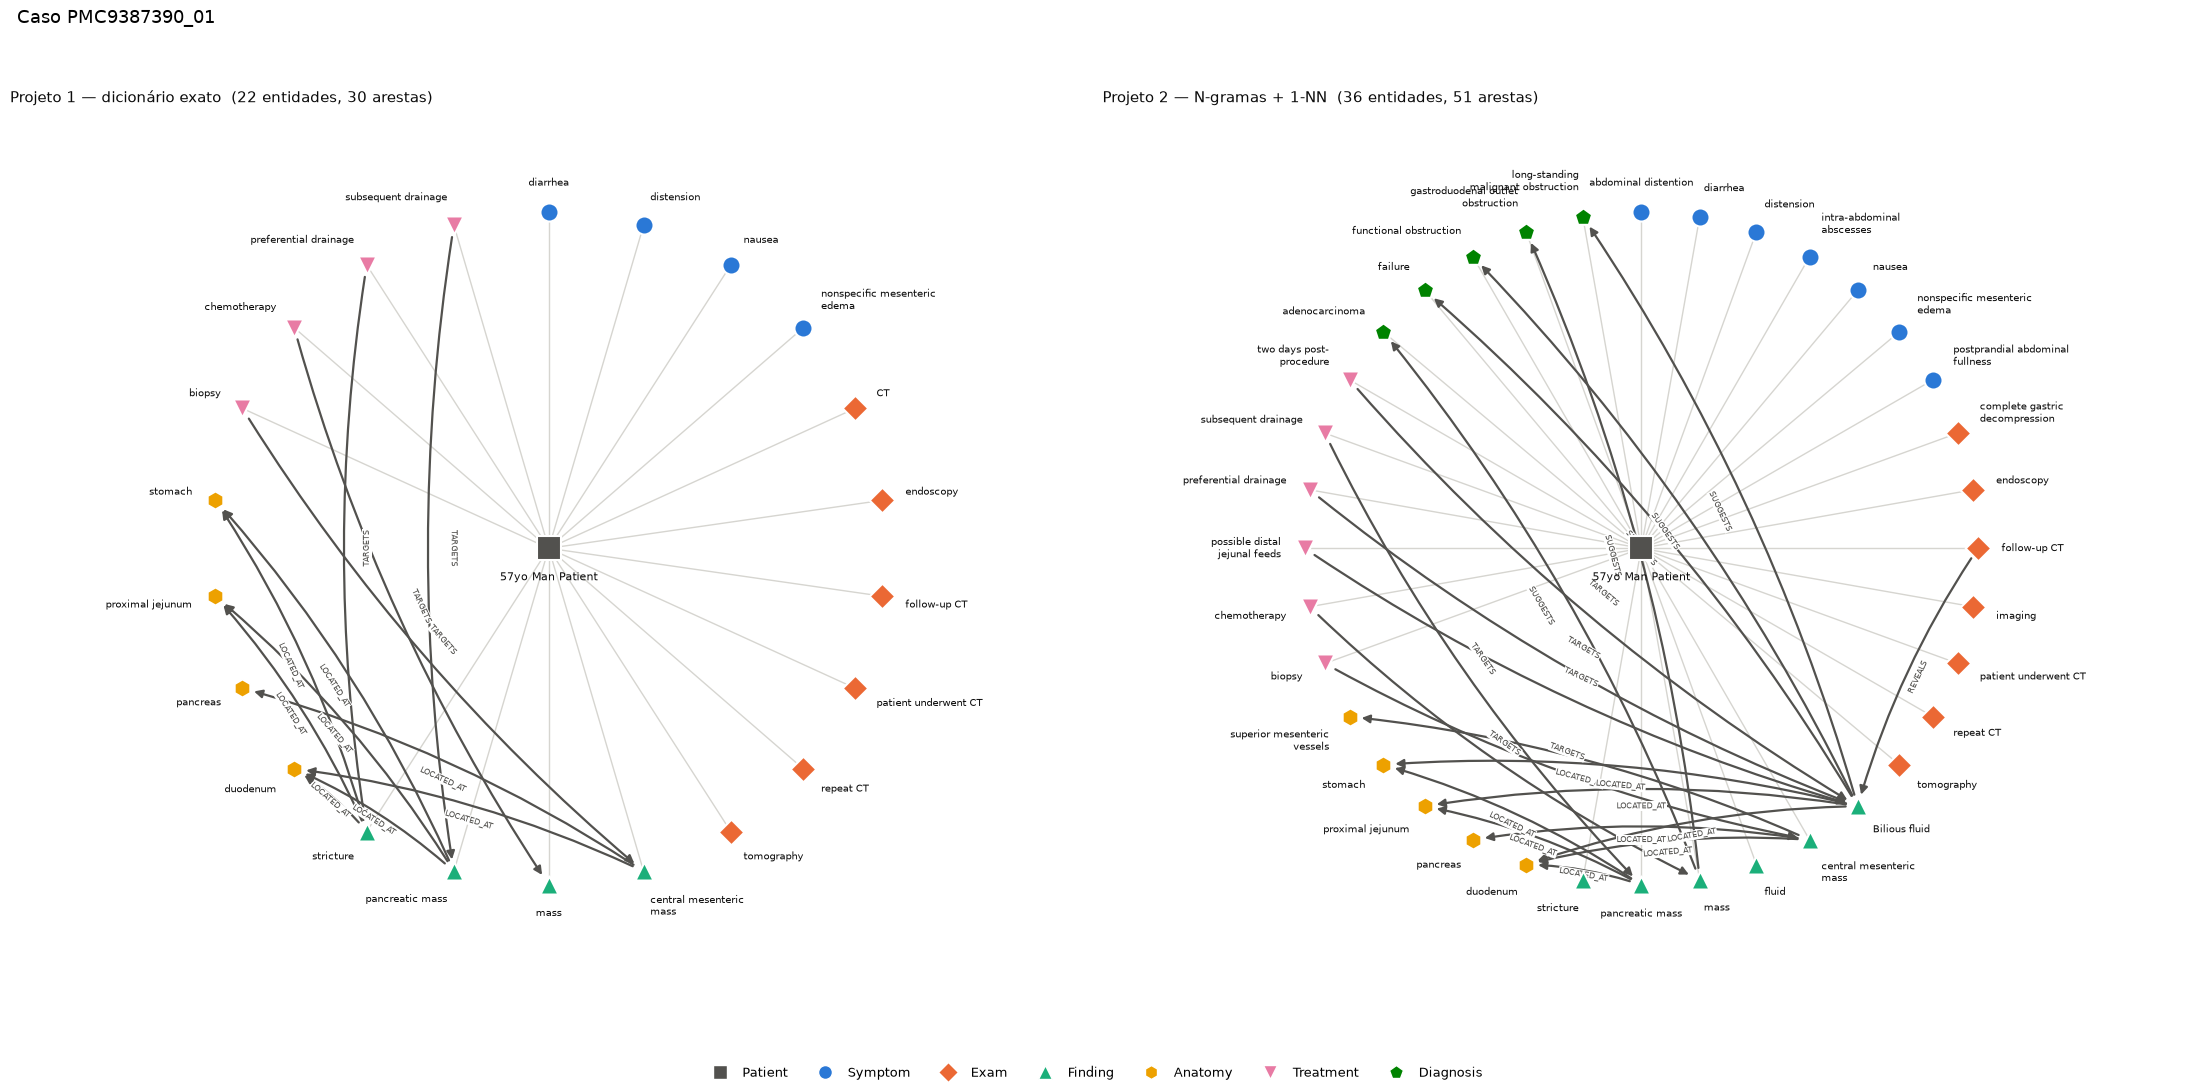

In [12]:
# Paleta categórica validada (ordem fixa) + forma por tipo como codificação secundária
STYLE = {
    "Patient":    ("#52514e", "s"),
    "Symptom":    ("#2a78d6", "o"),
    "Exam":       ("#eb6834", "D"),
    "Finding":    ("#1baf7a", "^"),
    "Anatomy":    ("#eda100", "h"),
    "Treatment":  ("#e87ba4", "v"),
    "Diagnosis":  ("#008300", "p"),
    "Outcome":    ("#6250d6", "*"),
    "ExamResult": ("#e34948", "8"),
}

def draw_graph(g, ax, title):
    # Paciente no centro; entidades num círculo, agrupadas por tipo
    order = list(STYLE)
    ring = sorted((n for n, d in g.nodes(data=True) if d.get("entity_type") != "Patient"),
                  key=lambda n: (order.index(g.nodes[n]["entity_type"]), n.lower()))
    angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, len(ring), endpoint=False)
    pos = {n: (np.cos(a), np.sin(a)) for n, a in zip(ring, angles)}
    pos["P1"] = (0.0, 0.0)
    patient_edges = [(u, v) for u, v in g.edges() if "P1" in (u, v)]
    entity_edges = [(u, v) for u, v in g.edges() if "P1" not in (u, v)]
    nx.draw_networkx_edges(g, pos, edgelist=patient_edges, ax=ax, edge_color="#d6d5d0", width=1, arrows=False)
    nx.draw_networkx_edges(g, pos, edgelist=entity_edges, ax=ax, edge_color="#52514e", width=1.6,
                           arrowsize=12, connectionstyle="arc3,rad=0.08")
    nx.draw_networkx_edge_labels(g, pos, edge_labels={(u, v): g.edges[u, v]["label"] for u, v in entity_edges},
                                 ax=ax, font_size=6, font_color="#52514e", bbox=dict(fc="white", ec="none", pad=0.5))
    present = []
    for etype, (color, shape) in STYLE.items():
        nodes = [n for n, d in g.nodes(data=True) if d.get("entity_type") == etype]
        if nodes:
            present.append(etype)
            nx.draw_networkx_nodes(g, pos, nodelist=nodes, ax=ax, node_color=color, node_shape=shape,
                                   node_size=320 if etype == "Patient" else 170, edgecolors="white", linewidths=1.5)
    for n, d in g.nodes(data=True):
        x, y = pos[n]
        label = textwrap.fill(d.get("label", n), 22)
        if n == "P1":
            ax.text(0, -0.07, label, ha="center", va="top", fontsize=8, color="#0b0b0b")
        else:  # rótulo do lado de fora do círculo
            ax.text(1.07 * x, 1.07 * y, label, fontsize=7, color="#0b0b0b",
                    ha="left" if x > 0.05 else "right" if x < -0.05 else "center",
                    va="bottom" if y > 0.05 else "top" if y < -0.05 else "center")
    ax.set_title(title, fontsize=11, loc="left", color="#0b0b0b")
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal")
    ax.axis("off")
    return present

fig, axes = plt.subplots(1, 2, figsize=(22, 11))
present = set(draw_graph(g1, axes[0], f"Projeto 1 — dicionário exato  ({len(e1)} entidades, {g1.number_of_edges()} arestas)"))
present |= set(draw_graph(g2, axes[1], f"Projeto 2 — N-gramas + 1-NN  ({len(e2)} entidades, {g2.number_of_edges()} arestas)"))
handles = [plt.Line2D([], [], marker=STYLE[t][1], color="none", markerfacecolor=STYLE[t][0],
                      markeredgecolor="white", markersize=10, label=t) for t in STYLE if t in present]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=9)
fig.suptitle(f"Caso {case['case_id']}", fontsize=13, x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

## 5. Sensibilidade ao limiar de similaridade

O limiar de 0,35 controla a troca entre **cobertura** e **ruído**: limiares baixos aceitam sintagmas que compartilham poucos n-gramas com um protótipo; limiares altos aproximam o Projeto 2 de uma busca exata. A linha tracejada é o Projeto 1 no mesmo caso.

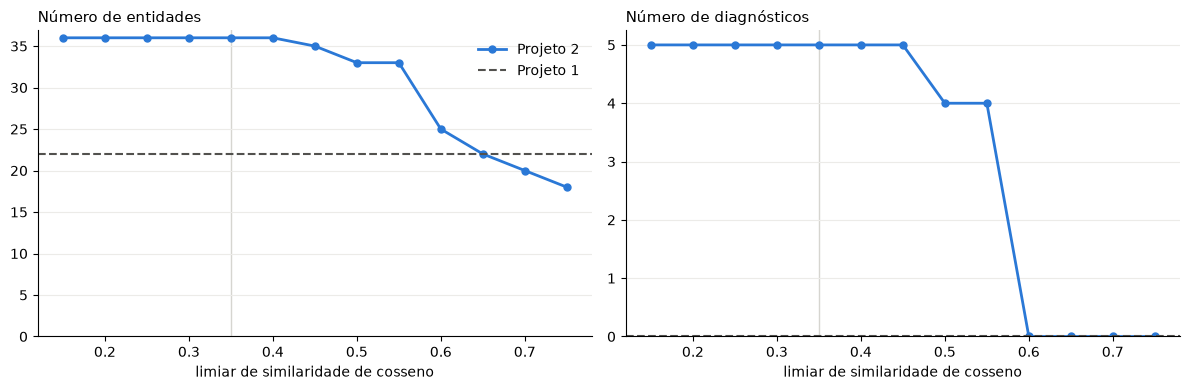

,limiar,entidades,diagnósticos,em comum com P1
0,0.15,36,5,21
1,0.20,36,5,21
2,0.25,36,5,21
3,0.30,36,5,21
4,0.35,36,5,21
5,0.40,36,5,21
6,0.45,35,5,21
7,0.50,33,4,21
8,0.55,33,4,21
9,0.60,25,0,21


In [13]:
thresholds = np.round(np.arange(0.15, 0.80, 0.05), 2)
sweep = []
for t in thresholds:
    ents = entities(run_p2(text, t))
    sweep.append({"limiar": t, "entidades": len(ents),
                  "diagnósticos": sum(1 for _, et in ents if et == "Diagnosis"),
                  "em comum com P1": len(ents & e1)})
sweep = pd.DataFrame(sweep)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, col, p1_value in [(axes[0], "entidades", len(e1)),
                          (axes[1], "diagnósticos", sum(1 for _, t in e1 if t == "Diagnosis"))]:
    ax.plot(sweep["limiar"], sweep[col], color="#2a78d6", lw=2, marker="o", ms=5, label="Projeto 2")
    ax.axhline(p1_value, color="#52514e", lw=1.5, ls="--", label="Projeto 1")
    ax.axvline(0.35, color="#d6d5d0", lw=1, zorder=0)
    ax.set_title(f"Número de {col}", loc="left", fontsize=11)
    ax.set_xlabel("limiar de similaridade de cosseno")
    ax.grid(axis="y", color="#ecebe8"); ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
sweep

## 6. Comparação em vários casos do MultiCaRe

Os dois pipelines são executados nos primeiros `N_CASES` casos da amostra. Sem anotação de referência não há precisão/revocação; medimos **cobertura** (entidades por tipo) e **sobreposição** (índice de Jaccard entre os conjuntos de entidades de cada caso).

In [14]:
N_CASES = 30

rows, totals = [], {"Projeto 1": dict.fromkeys(TYPES, 0), "Projeto 2": dict.fromkeys(TYPES, 0)}
for idx in range(min(N_CASES, len(cases))):
    t = cases.loc[idx, "case_text"]
    a, b = entities(p1.build_generic_graph(t)), entities(run_p2(t, THRESHOLD))
    for name, ents in [("Projeto 1", a), ("Projeto 2", b)]:
        for _, et in ents:
            totals[name][et] += 1
    rows.append({"case_id": cases.loc[idx, "case_id"], "P1": len(a), "P2": len(b),
                 "comum": len(a & b), "jaccard": len(a & b) / len(a | b) if a | b else 1.0})
per_case = pd.DataFrame(rows)
by_type = pd.DataFrame(totals).loc[[t for t in TYPES if sum(totals[p][t] for p in totals) > 0]]

print(f"Média de entidades por caso: P1 = {per_case.P1.mean():.1f} | P2 = {per_case.P2.mean():.1f}")
print(f"Jaccard médio entre P1 e P2: {per_case.jaccard.mean():.2f}")
print(f"Casos em que P2 encontrou mais entidades: {(per_case.P2 > per_case.P1).sum()} de {len(per_case)}")

Média de entidades por caso: P1 = 14.0 | P2 = 21.4
Jaccard médio entre P1 e P2: 0.64
Casos em que P2 encontrou mais entidades: 27 de 30


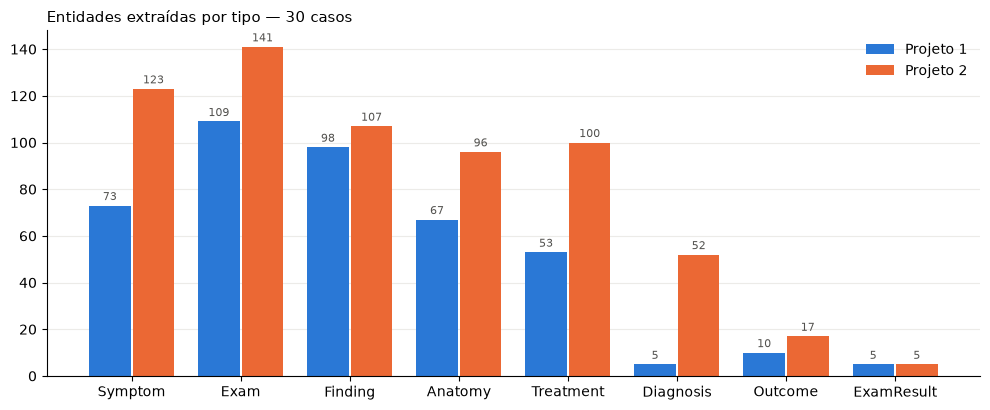

,Projeto 1,Projeto 2
Symptom,73,123
Exam,109,141
Finding,98,107
Anatomy,67,96
Treatment,53,100
Diagnosis,5,52
Outcome,10,17
ExamResult,5,5


In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(by_type))
w = 0.38
for i, (name, color) in enumerate([("Projeto 1", "#2a78d6"), ("Projeto 2", "#eb6834")]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), by_type[name], width=w, color=color, label=name)
    ax.bar_label(bars, fontsize=8, color="#52514e", padding=2)
ax.set_xticks(x, by_type.index)
ax.set_title(f"Entidades extraídas por tipo — {len(per_case)} casos", loc="left", fontsize=11)
ax.grid(axis="y", color="#ecebe8"); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
by_type

In [16]:
per_case

,case_id,P1,P2,comum,jaccard
0,PMC5137649_01,33,39,33,0.846154
1,PMC9387390_01,22,36,21,0.567568
2,PMC3437073_01,16,23,16,0.695652
3,PMC7102447_01,13,18,13,0.722222
4,PMC6354154_01,13,16,13,0.812500
5,PMC4782471_01,15,23,15,0.652174
6,PMC4835621_01,32,45,31,0.673913
7,PMC8627357_01,19,29,18,0.600000
8,PMC5833205_01,12,21,12,0.571429
9,PMC3917415_01,6,8,5,0.555556


## Conclusão

* O classificador por N-gramas **amplia a cobertura** do grafo, em especial de diagnósticos, que a busca exata raramente encontra porque os textos usam variações dos termos do vocabulário.
* O custo são erros previsíveis por **n-gramas compartilhados** (*failure* ↔ *renal failure*) e pela ausência de *stemming* (*abscesses* ≠ *abscess*), visíveis na seção 3.
* A seção 5 mostra que o limiar é o controle direto entre cobertura e ruído; a seção 6 verifica se o comportamento observado no caso estudado se repete em outros casos.